In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.multivariate.manova import MANOVA
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix

In [3]:
# ==========================================
# 1. READ DIRECTLY FROM EXCEL & CLEAN DATA
# ==========================================
df = pd.read_excel('Group_2_MANOVA.xlsx', sheet_name='Sheet1')
df.columns = df.columns.str.strip()

# Let's inspect the actual column names to avoid KeyErrors
print("Available columns in the dataset:", df.columns.tolist())

# Adjust these column names based on the printed output above.
# Typically, if they are 'sepal length (cm)', etc., we can map them:
rename_map = {
    'sepal length (cm)': 'SL',
    'sepal width (cm)': 'SW',
    'petal length (cm)': 'PL',
    'petal width (cm)': 'PW',
    'species': 'Species' # Adjust if the column is named 'target', 'class', or 'species'
}

# Rename columns if they exist in our map, otherwise keep original
df = df.rename(columns=rename_map)

# Fallback: check which of our target columns are actually present in the DataFrame
target_cols = [col for col in ['SL', 'SW', 'PL', 'PW', 'Species'] if col in df.columns]

df_clean = df.dropna(subset=target_cols).copy()
print("\nCleaned DataFrame shape:", df_clean.shape)
print(df_clean.head())

Available columns in the dataset: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'species', 'Group_4_Prediction', 'Unnamed: 6', 'iris-setosa', 'iris-versicolor', 'iris-vriginia']

Cleaned DataFrame shape: (150, 10)
    SL   SW   PL   PW      Species Group_4_Prediction  Unnamed: 6  \
0  5.1  3.5  1.4  0.2  Iris-setosa        Iris-setosa         NaN   
1  4.9  3.0  1.4  0.2  Iris-setosa        Iris-setosa         NaN   
2  4.7  3.2  1.3  0.2  Iris-setosa        Iris-setosa         NaN   
3  4.6  3.1  1.5  0.2  Iris-setosa        Iris-setosa         NaN   
4  5.0  3.6  1.4  0.2  Iris-setosa        Iris-setosa         NaN   

   iris-setosa  iris-versicolor  iris-vriginia  
0         50.0              0.0            0.0  
1          0.0             48.0            2.0  
2          0.0              4.0           46.0  
3          NaN              NaN            NaN  
4          NaN             96.0            NaN  


=== GROUP 2 MANOVA RESULTS ===
                   Multivariate linear model
                                                                
----------------------------------------------------------------
       Intercept         Value  Num DF  Den DF   F Value  Pr > F
----------------------------------------------------------------
          Wilks' lambda  0.0170 4.0000 144.0000 2080.5278 0.0000
         Pillai's trace  0.9830 4.0000 144.0000 2080.5278 0.0000
 Hotelling-Lawley trace 57.7924 4.0000 144.0000 2080.5278 0.0000
    Roy's greatest root 57.7924 4.0000 144.0000 2080.5278 0.0000
----------------------------------------------------------------
                                                                
----------------------------------------------------------------
        Species          Value  Num DF  Den DF   F Value  Pr > F
----------------------------------------------------------------
          Wilks' lambda  0.0235 8.0000 288.0000  198.7110 0.0000
         Pilla

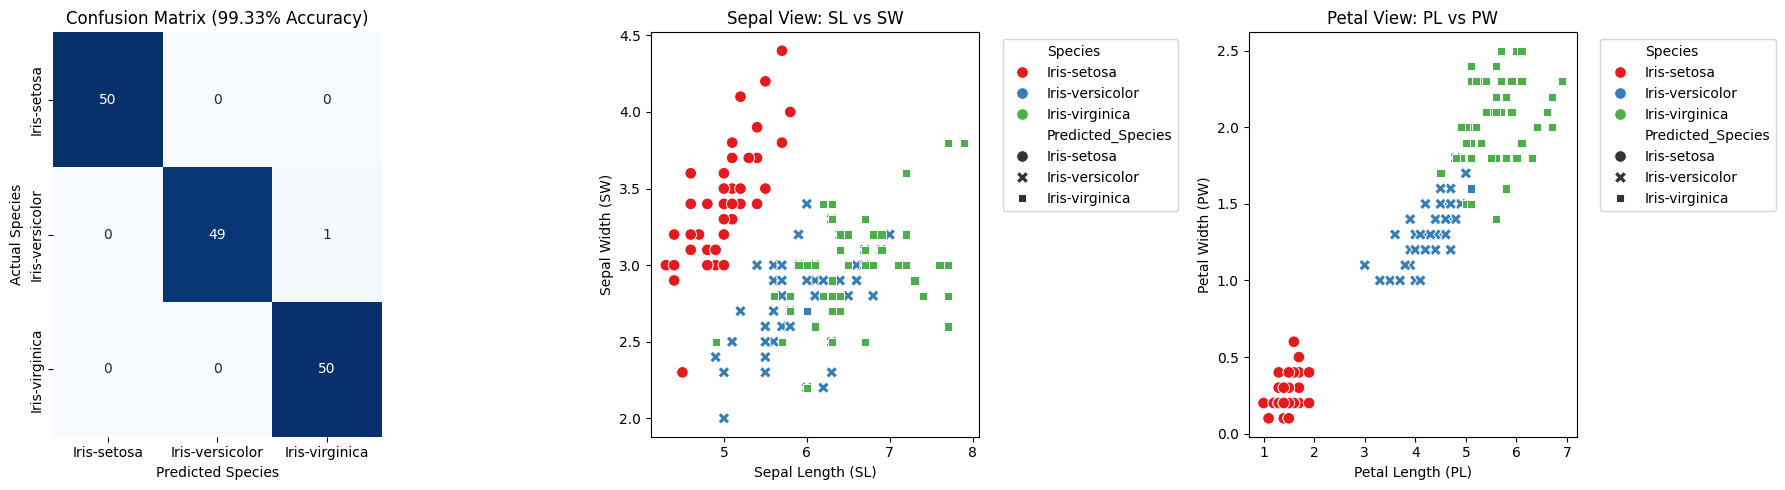


Generating All-Features Pairplot Grid (SL, SW, PL, PW)...


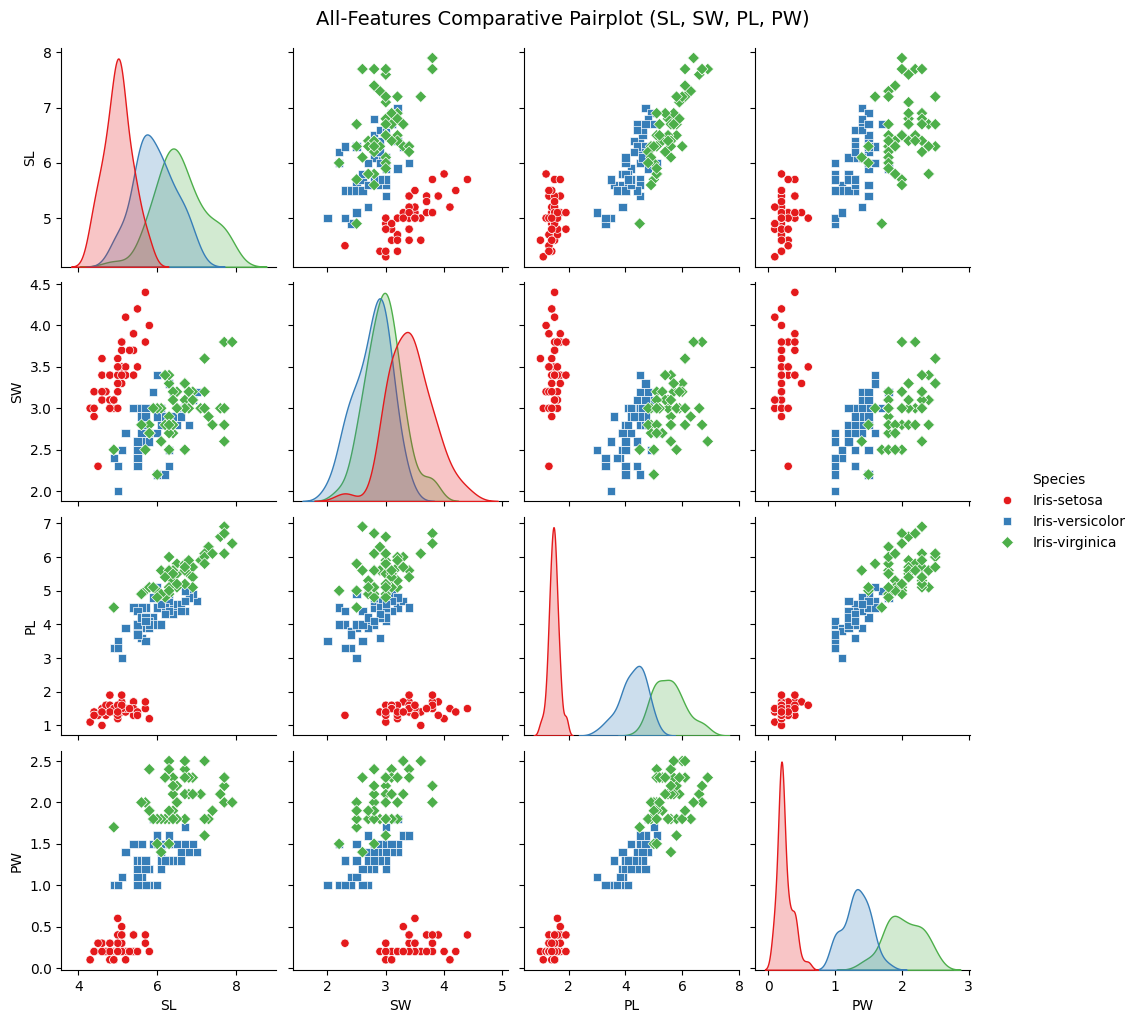


Success! Results saved directly to 'Group_2_Python_Results.xlsx'.


In [4]:
# ==========================================
# 2. RUN GROUP 2 MANOVA
# ==========================================
ma = MANOVA.from_formula('SL + SW + PL + PW ~ Species', data=df_clean)
print("=== GROUP 2 MANOVA RESULTS ===")
print(ma.mv_test().summary())

# ==========================================
# 3. TRAIN 4-FEATURE SVM & PREDICT
# ==========================================
X = df_clean[['SL', 'SW', 'PL', 'PW']]
y = df_clean['Species']

svm_model = SVC(kernel='linear', C=1.0)
svm_model.fit(X, y)
df_clean['Predicted_Species'] = svm_model.predict(X)

acc = accuracy_score(y, df_clean['Predicted_Species'])
print(f"\nGroup 2 Multivariate SVM Accuracy: {acc * 100:.2f}%")

# ==========================================
# 4. GENERATE 3-PANEL DIAGNOSTIC PLOTS
# (Confusion Matrix, Sepal View, Petal View)
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel A: Confusion Matrix Heatmap
cm = confusion_matrix(df_clean['Species'], df_clean['Predicted_Species'])
species_labels = sorted(df_clean['Species'].unique())
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=species_labels, yticklabels=species_labels, ax=axes[0])
axes[0].set_title(f'Confusion Matrix ({acc * 100:.2f}% Accuracy)')
axes[0].set_xlabel('Predicted Species')
axes[0].set_ylabel('Actual Species')

# Panel B: Sepal View (SL vs SW)
sns.scatterplot(data=df_clean, x='SL', y='SW', hue='Species',
                style='Predicted_Species', palette='Set1', s=70, ax=axes[1])
axes[1].set_title('Sepal View: SL vs SW')
axes[1].set_xlabel('Sepal Length (SL)')
axes[1].set_ylabel('Sepal Width (SW)')
axes[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left')

# Panel C: Petal View (PL vs PW)
sns.scatterplot(data=df_clean, x='PL', y='PW', hue='Species',
                style='Predicted_Species', palette='Set1', s=70, ax=axes[2])
axes[2].set_title('Petal View: PL vs PW')
axes[2].set_xlabel('Petal Length (PL)')
axes[2].set_ylabel('Petal Width (PW)')
axes[2].legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

# ==========================================
# 5. GENERATE ALL-FEATURES PAIRPLOT GRID
# ==========================================
print("\nGenerating All-Features Pairplot Grid (SL, SW, PL, PW)...")
g = sns.pairplot(
    df_clean,
    vars=['SL', 'SW', 'PL', 'PW'],
    hue='Species',
    palette='Set1',
    diag_kind='kde',
    markers=["o", "s", "D"]
)
g.fig.suptitle("All-Features Comparative Pairplot (SL, SW, PL, PW)", y=1.02, fontsize=14)
plt.show()

# ==========================================
# 6. SAVE RESULTS BACK TO EXCEL
# ==========================================
df_clean.to_excel('Group_2_Python_Results.xlsx', index=False)
print("\nSuccess! Results saved directly to 'Group_2_Python_Results.xlsx'.")

In [6]:
from sklearn.neighbors import KNeighborsClassifier

In [9]:
knn_model = KNeighborsClassifier(n_neighbors=3)
knn_model.fit(X, y)
df_clean['Predicted_Species'] = knn_model.predict(X)

acc = accuracy_score(y, df_clean['Predicted_Species'])
print(f"\nGroup 2 Multivariate KNN Accuracy: {acc * 100:.2f}%")


Group 2 Multivariate KNN Accuracy: 96.00%


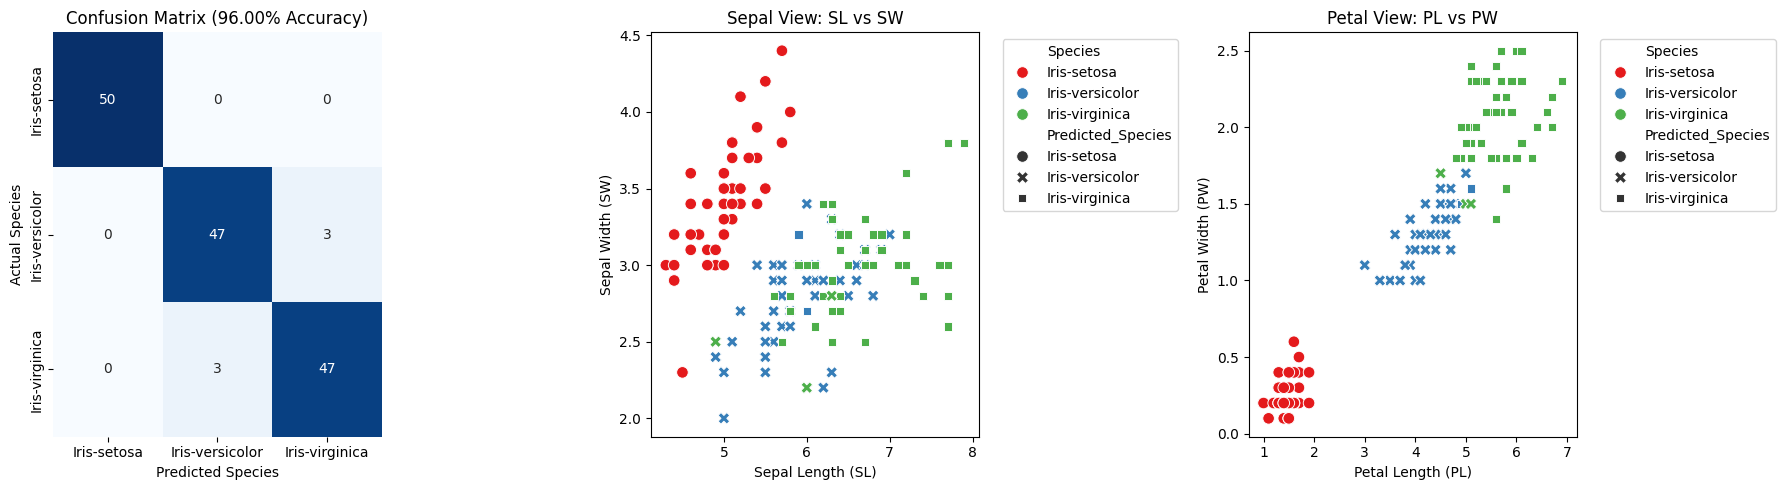


Generating All-Features Pairplot Grid (SL, SW, PL, PW)...


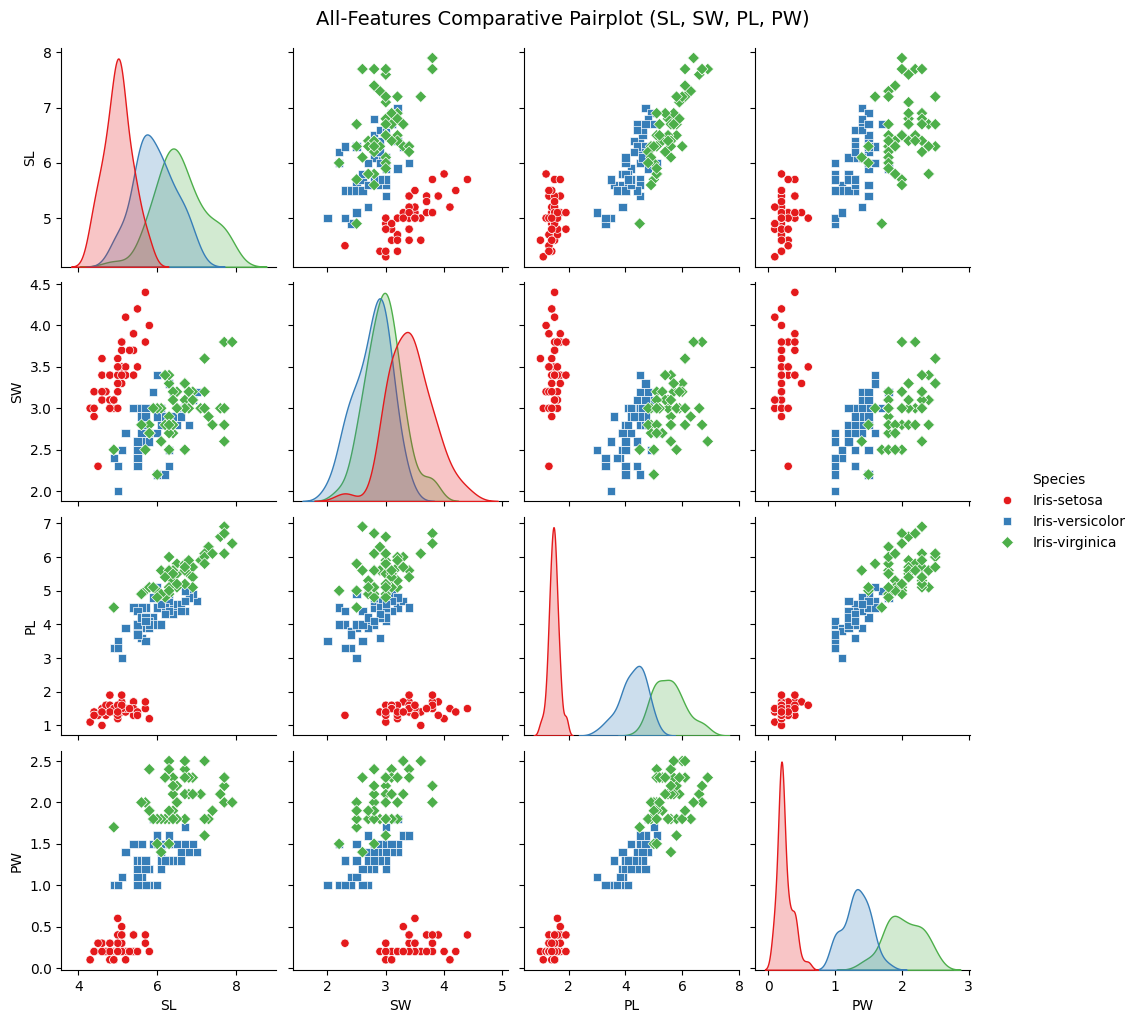


Success! Results saved directly to 'Group_2_Python_Results.xlsx'.


In [10]:

# ==========================================
# 4. GENERATE 3-PANEL DIAGNOSTIC PLOTS
# (Confusion Matrix, Sepal View, Petal View)
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel A: Confusion Matrix Heatmap
cm = confusion_matrix(df_clean['Species'], df_clean['Predicted_Species'])
species_labels = sorted(df_clean['Species'].unique())
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=species_labels, yticklabels=species_labels, ax=axes[0])
axes[0].set_title(f'Confusion Matrix ({acc * 100:.2f}% Accuracy)')
axes[0].set_xlabel('Predicted Species')
axes[0].set_ylabel('Actual Species')

# Panel B: Sepal View (SL vs SW)
sns.scatterplot(data=df_clean, x='SL', y='SW', hue='Species',
                style='Predicted_Species', palette='Set1', s=70, ax=axes[1])
axes[1].set_title('Sepal View: SL vs SW')
axes[1].set_xlabel('Sepal Length (SL)')
axes[1].set_ylabel('Sepal Width (SW)')
axes[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left')

# Panel C: Petal View (PL vs PW)
sns.scatterplot(data=df_clean, x='PL', y='PW', hue='Species',
                style='Predicted_Species', palette='Set1', s=70, ax=axes[2])
axes[2].set_title('Petal View: PL vs PW')
axes[2].set_xlabel('Petal Length (PL)')
axes[2].set_ylabel('Petal Width (PW)')
axes[2].legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

# ==========================================
# 5. GENERATE ALL-FEATURES PAIRPLOT GRID
# ==========================================
print("\nGenerating All-Features Pairplot Grid (SL, SW, PL, PW)...")
g = sns.pairplot(
    df_clean,
    vars=['SL', 'SW', 'PL', 'PW'],
    hue='Species',
    palette='Set1',
    diag_kind='kde',
    markers=["o", "s", "D"]
)
g.fig.suptitle("All-Features Comparative Pairplot (SL, SW, PL, PW)", y=1.02, fontsize=14)
plt.show()

# ==========================================
# 6. SAVE RESULTS BACK TO EXCEL
# ==========================================
df_clean.to_excel('Group_2_Python_Results.xlsx', index=False)
print("\nSuccess! Results saved directly to 'Group_2_Python_Results.xlsx'.")

In [11]:
from sklearn.ensemble import RandomForestClassifier
# ==========================================
# 3. TRAIN 4-FEATURE RANDOM FOREST & PREDICT
# ==========================================
X = df_clean[['SL', 'SW', 'PL', 'PW']]
y = df_clean['Species']

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X, y)
df_clean['Predicted_Species'] = rf_model.predict(X)

acc = accuracy_score(y, df_clean['Predicted_Species'])
print(f"\nGroup 2 Multivariate Random Forest Accuracy: {acc * 100:.2f}%")


Group 2 Multivariate Random Forest Accuracy: 100.00%


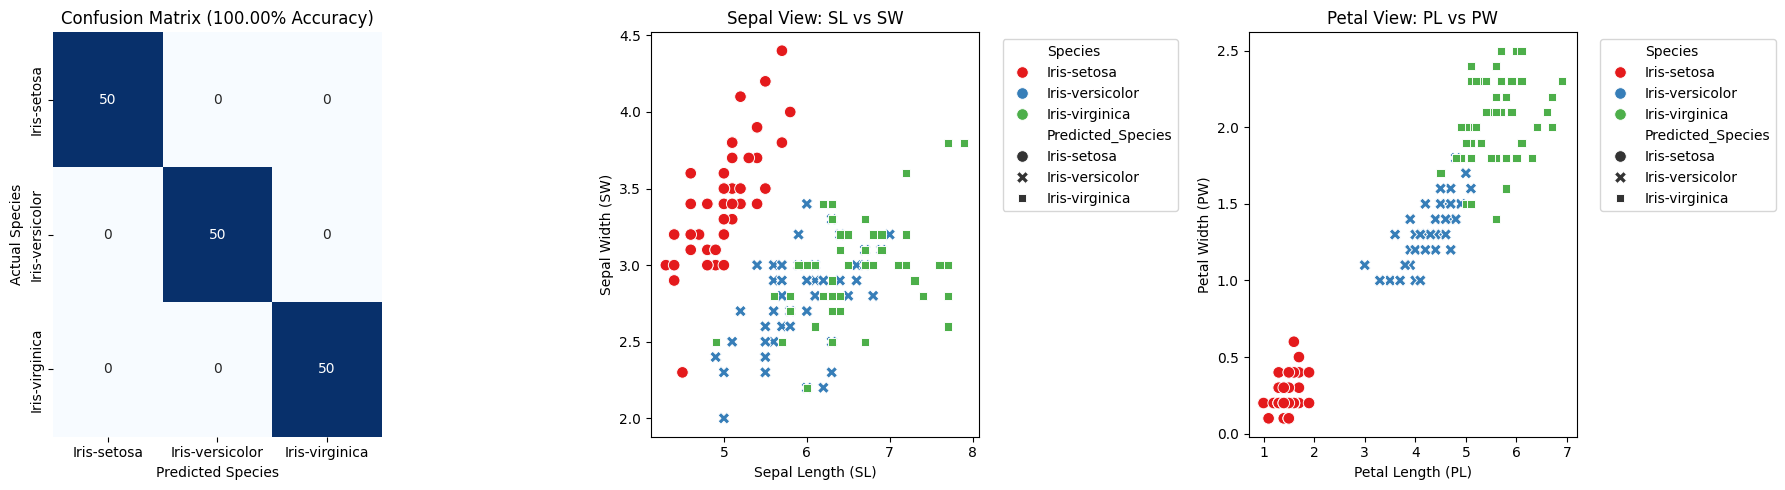


Generating All-Features Pairplot Grid (SL, SW, PL, PW)...


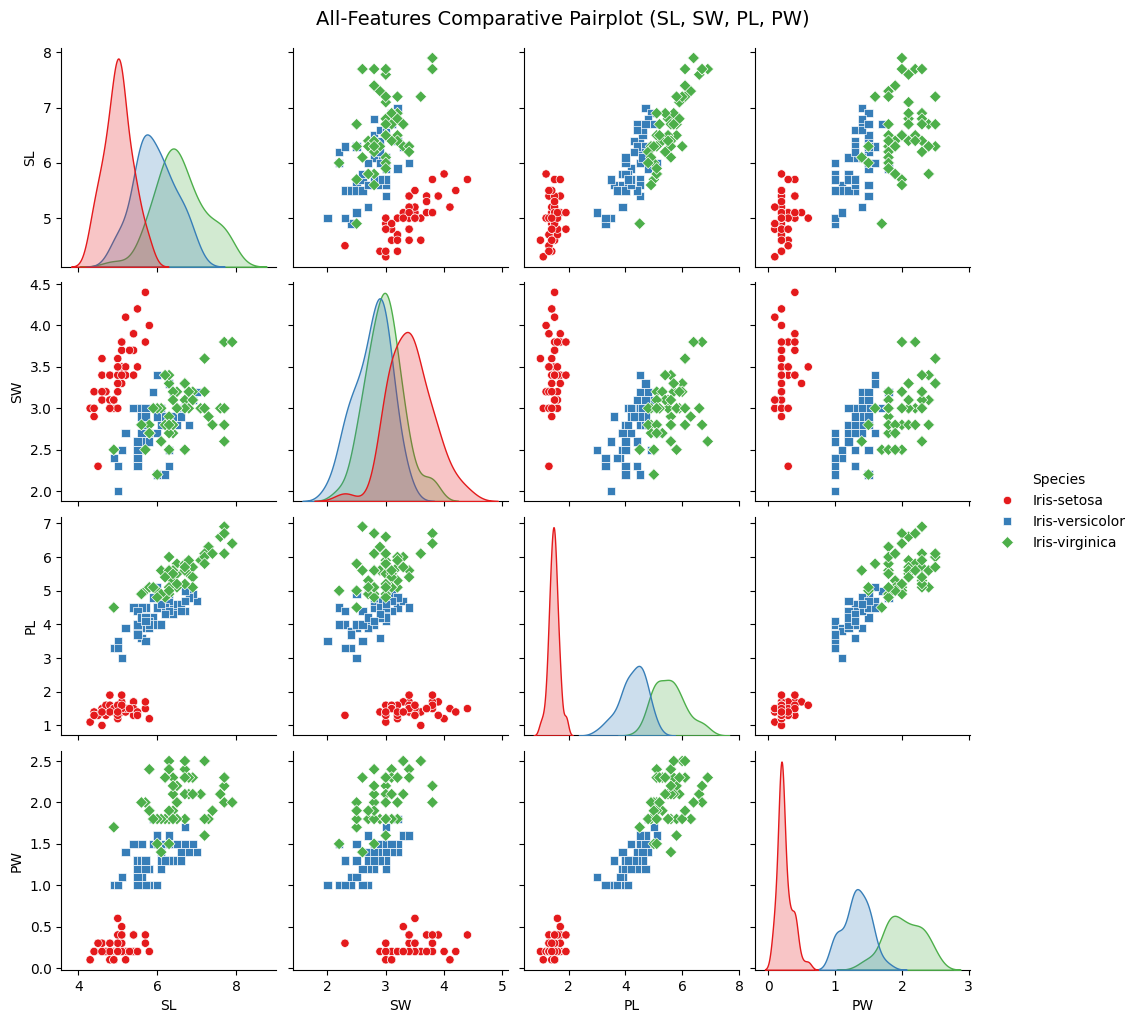


Success! Results saved directly to 'Group_2_Python_Results.xlsx'.


In [12]:

# ==========================================
# 4. GENERATE 3-PANEL DIAGNOSTIC PLOTS
# (Confusion Matrix, Sepal View, Petal View)
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel A: Confusion Matrix Heatmap
cm = confusion_matrix(df_clean['Species'], df_clean['Predicted_Species'])
species_labels = sorted(df_clean['Species'].unique())
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=species_labels, yticklabels=species_labels, ax=axes[0])
axes[0].set_title(f'Confusion Matrix ({acc * 100:.2f}% Accuracy)')
axes[0].set_xlabel('Predicted Species')
axes[0].set_ylabel('Actual Species')

# Panel B: Sepal View (SL vs SW)
sns.scatterplot(data=df_clean, x='SL', y='SW', hue='Species',
                style='Predicted_Species', palette='Set1', s=70, ax=axes[1])
axes[1].set_title('Sepal View: SL vs SW')
axes[1].set_xlabel('Sepal Length (SL)')
axes[1].set_ylabel('Sepal Width (SW)')
axes[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left')

# Panel C: Petal View (PL vs PW)
sns.scatterplot(data=df_clean, x='PL', y='PW', hue='Species',
                style='Predicted_Species', palette='Set1', s=70, ax=axes[2])
axes[2].set_title('Petal View: PL vs PW')
axes[2].set_xlabel('Petal Length (PL)')
axes[2].set_ylabel('Petal Width (PW)')
axes[2].legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

# ==========================================
# 5. GENERATE ALL-FEATURES PAIRPLOT GRID
# ==========================================
print("\nGenerating All-Features Pairplot Grid (SL, SW, PL, PW)...")
g = sns.pairplot(
    df_clean,
    vars=['SL', 'SW', 'PL', 'PW'],
    hue='Species',
    palette='Set1',
    diag_kind='kde',
    markers=["o", "s", "D"]
)
g.fig.suptitle("All-Features Comparative Pairplot (SL, SW, PL, PW)", y=1.02, fontsize=14)
plt.show()

# ==========================================
# 6. SAVE RESULTS BACK TO EXCEL
# ==========================================
df_clean.to_excel('Group_2_Python_Results.xlsx', index=False)
print("\nSuccess! Results saved directly to 'Group_2_Python_Results.xlsx'.")

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

# Initialize the models
models = {
    "Logistic Regression": LogisticRegression(max_iter=200, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Gaussian Naive Bayes": GaussianNB(),
    "Multi-layer Perceptron (NN)": MLPClassifier(max_iter=500, random_state=42)
}

# Train and evaluate each model
print("=== Additional Algorithms Accuracy ===")
for name, model in models.items():
    model.fit(X, y)
    predictions = model.predict(X)
    accuracy = accuracy_score(y, predictions)
    print(f"{name}: {accuracy * 100:.2f}%")

=== Additional Algorithms Accuracy ===
Logistic Regression: 97.33%
Decision Tree: 100.00%
Gradient Boosting: 100.00%
Gaussian Naive Bayes: 96.00%
Multi-layer Perceptron (NN): 98.00%


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier

# Neural networks perform best when input features are standardized (scaled)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Initialize an Artificial Neural Network (MLPClassifier)
# Here we define a network with 2 hidden layers: the first has 8 neurons, and the second has 4 neurons
ann_model = MLPClassifier(
    hidden_layer_sizes=(8, 4),
    activation='relu',
    solver='adam',
    max_iter=1000,
    random_state=42
)

# Train the ANN
ann_model.fit(X_scaled, y)

# Predict and calculate accuracy
df_clean['Predicted_Species_ANN'] = ann_model.predict(X_scaled)
ann_acc = accuracy_score(y, df_clean['Predicted_Species_ANN'])

print(f"=== ANN Classifier Results ===")
print(f"Network Architecture: Input (4 features) -> Hidden (8 neurons) -> Hidden (4 neurons) -> Output (3 classes)")
print(f"ANN Classification Accuracy: {ann_acc * 100:.2f}%")

=== ANN Classifier Results ===
Network Architecture: Input (4 features) -> Hidden (8 neurons) -> Hidden (4 neurons) -> Output (3 classes)
ANN Classification Accuracy: 94.67%


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


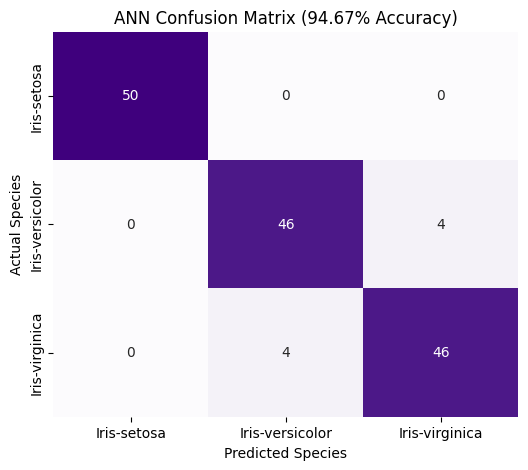

In [15]:
# Plot the ANN's confusion matrix
plt.figure(figsize=(6, 5))
cm_ann = confusion_matrix(df_clean['Species'], df_clean['Predicted_Species_ANN'])
sns.heatmap(cm_ann, annot=True, fmt='d', cmap='Purples', cbar=False,
            xticklabels=species_labels, yticklabels=species_labels)
plt.title(f'ANN Confusion Matrix ({ann_acc * 100:.2f}% Accuracy)')
plt.xlabel('Predicted Species')
plt.ylabel('Actual Species')
plt.show()

In [16]:
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

# ==========================================
# 7. TRAIN 4-FEATURE ANN & PREDICT
# ==========================================

# Standardizing features is highly recommended for ANN training convergence
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train Multi-Layer Perceptron (ANN) Classifier with (10, 10) layer structure
ann_model = MLPClassifier(hidden_layer_sizes=(10, 10), max_iter=1000, random_state=42)
ann_model.fit(X_scaled, y)

df_clean['Predicted_Species'] = ann_model.predict(X_scaled)

acc = accuracy_score(y, df_clean['Predicted_Species'])
print(f"\nGroup 2 Multivariate ANN (10, 10) Accuracy: {acc * 100:.2f}%")


Group 2 Multivariate ANN (10, 10) Accuracy: 97.33%


=== FINAL MODEL COMPARISON ===


,Model,Accuracy (%)
0,Decision Tree,100.000000
1,Random Forest,100.000000
2,Gradient Boosting,100.000000
3,Linear SVM,99.333333
4,Multi-layer Perceptron (NN),98.000000
5,Logistic Regression,97.333333
6,"Optimized ANN (10, 10)",97.333333
7,K-Nearest Neighbors,96.000000
8,Gaussian Naive Bayes,96.000000
9,"ANN (8, 4)",94.666667


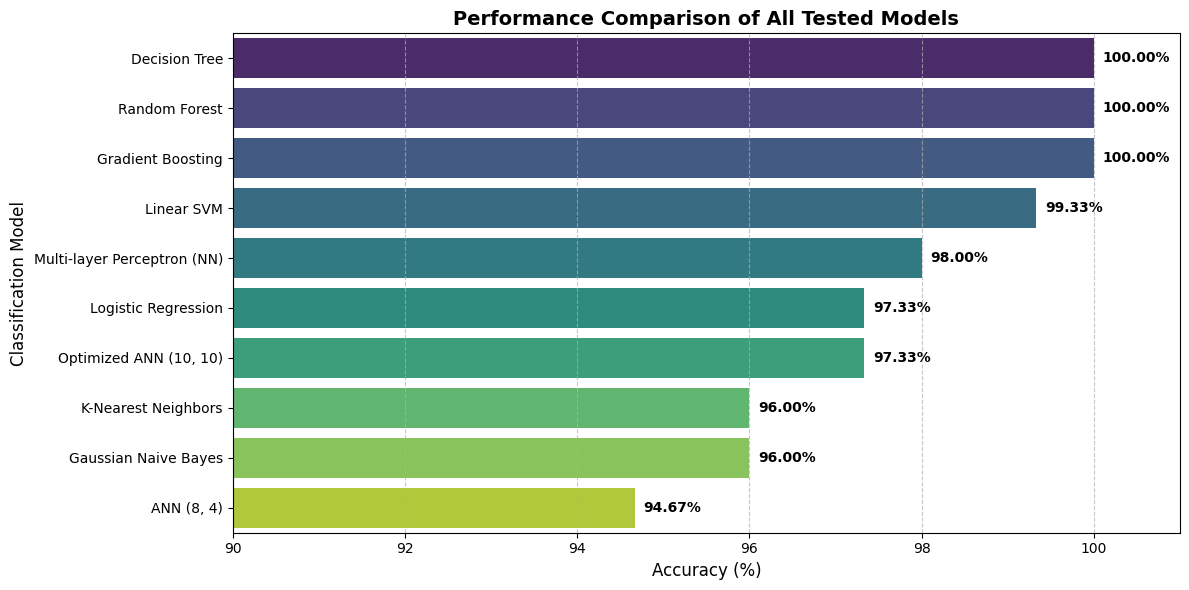

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score

# Gather predictions and calculate exact accuracy for all tested models
results_dict = {}

# 1. Linear SVM
svm_pred = svm_model.predict(X)
results_dict['Linear SVM'] = accuracy_score(y, svm_pred) * 100

# 2. KNN (k=3)
knn_pred = knn_model.predict(X)
results_dict['K-Nearest Neighbors'] = accuracy_score(y, knn_pred) * 100

# 3. Random Forest
rf_pred = rf_model.predict(X)
results_dict['Random Forest'] = accuracy_score(y, rf_pred) * 100

# 4. Models from the dict loop (Logistic Regression, Decision Tree, Gradient Boosting, Naive Bayes, MLP)
for name, model in models.items():
    pred = model.predict(X)
    results_dict[name] = accuracy_score(y, pred) * 100

# 5. First ANN (8, 4) on scaled data
ann_8_4_pred = ann_model.predict(X_scaled)  # Note: 1fd04300 used scaled data
# Since variables might have been overwritten, we fetch directly from stored column if available
if 'Predicted_Species_ANN' in df_clean.columns:
    results_dict['ANN (8, 4)'] = accuracy_score(y, df_clean['Predicted_Species_ANN']) * 100

# 6. Optimized ANN (10, 10) on scaled data
results_dict['Optimized ANN (10, 10)'] = acc * 100

# Convert to DataFrame
df_results = pd.DataFrame(list(results_dict.items()), columns=['Model', 'Accuracy (%)']).sort_values(by='Accuracy (%)', ascending=False)

# Display the structured DataFrame
print("=== FINAL MODEL COMPARISON ===")
display(df_results.reset_index(drop=True))

# Plot the comparison
plt.figure(figsize=(12, 6))
sns.barplot(data=df_results, x='Accuracy (%)', y='Model', palette='viridis', hue='Model', legend=False)
plt.xlim(90, 101)
plt.title('Performance Comparison of All Tested Models', fontsize=14, fontweight='bold')
plt.xlabel('Accuracy (%)', fontsize=12)
plt.ylabel('Classification Model', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

for index, value in enumerate(df_results['Accuracy (%)']):
    plt.text(value + 0.1, index, f"{value:.2f}%", va='center', fontweight='bold')

plt.tight_layout()
plt.show()